# Invariants from symmetry eigenvalues
A crystal symmetry can fix a topological invariant from a few momenta only. We will now see two
examples. Take a point-group operation $g$, a rotation or the inversion, and a momentum $\vec k$
that $g$ maps onto itself, up to a reciprocal lattice vector. At such a momentum the Bloch states
are eigenstates of $g$, and their eigenvalues are the symmetry labels of the bands. They are
computed with `h.get_symmetry_eigenvalues(op,k)`.

In a two-dimensional insulator with a $C_3$ rotation the Chern number is fixed modulo 3 by the
$C_3$ eigenvalues $\theta_m$ of the occupied bands at $\Gamma$, $K$ and $K'$,

$$
e^{2\pi i C/3} = \prod_{m\in\text{occ}} (-1)^F\,\theta_m(\Gamma)\,\theta_m(K)\,\theta_m(K') ,
$$

with $F=1$ for a spinful Hamiltonian. This is `h.get_chern_mod_n()`, which also has the $C_2$,
$C_4$ and $C_6$ versions. With inversion and time reversal, the $Z_2$ invariant is
$(-1)^\nu=\prod_i\delta_i$, with $\delta_i$ the product of the inversion eigenvalues at the
time-reversal-invariant momentum $\Gamma_i$, one per Kramers pair. This is `h.get_parity_z2()`.

### Import the necessary libraries

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry
from pyqula import topology

### The C3 eigenvalues of the Haldane model
We take the Haldane model, which has a $C_3$ rotation about every site, and look at the $C_3$
eigenvalue of the occupied band at the three invariant momenta, for both signs of the Haldane
coupling.

In [2]:
g = geometry.honeycomb_lattice() # honeycomb lattice
op = topology.rotation_operation(3,center=g.r[0]) # C3 about a site
for t2 in [0.1,-0.1]:
    h = g.get_hamiltonian(has_spin=False) # first-neighbor hopping
    h.add_haldane(t2) # Haldane coupling
    for k in topology.invariant_momenta(h,op): # Gamma, K and K'
        ev = h.get_symmetry_eigenvalues(op,k) # C3 eigenvalue of the occupied band
        print("t2 =",t2,"  k =",np.round(k[:2],3),"  phase/(2pi/3) =",np.round(np.angle(ev)/(2*np.pi/3),3))
    print("t2 =",t2,"  C mod 3 =",h.get_chern_mod_n(n=3,center=g.r[0]),"  C =",round(h.get_chern(nk=30),3))

t2 = 0.1   k = [0. 0.]   phase/(2pi/3) = [0.]
t2 = 0.1   k = [0.333 0.333]   phase/(2pi/3) = [-0.]
t2 = 0.1   k = [0.667 0.667]   phase/(2pi/3) = [1.]
t2 = 0.1   C mod 3 = 1   C = 1.0
t2 = -0.1   k = [0. 0.]   phase/(2pi/3) = [0.]
t2 = -0.1   k = [0.333 0.333]   phase/(2pi/3) = [-1.]
t2 = -0.1   k = [0.667 0.667]   phase/(2pi/3) = [0.]


t2 = -0.1   C mod 3 = 2   C = -1.0


For $t_2=0.1$ the eigenvalue is $1$ at $\Gamma$ and at one valley, and $e^{2\pi i/3}$ at the other
valley, so $C=1$ modulo 3. For $t_2=-0.1$ the nontrivial label $e^{-2\pi i/3}$ moves to the other
valley, and the result is $2$, which is $C=-1$ modulo 3.

### Phase diagram of the Haldane model
Now we add a sublattice imbalance $M$, which keeps the $C_3$ rotation about a site, and map the
Chern number modulo 3 in the plane of $t_2$ and $M$. Each point needs three diagonalizations
only. On the gap-closing lines the occupied states are not a representation of the rotation at
$K$ or $K'$, and the call raises an error; we leave these points blank. A result $2$ is shown as
$C=-1$.

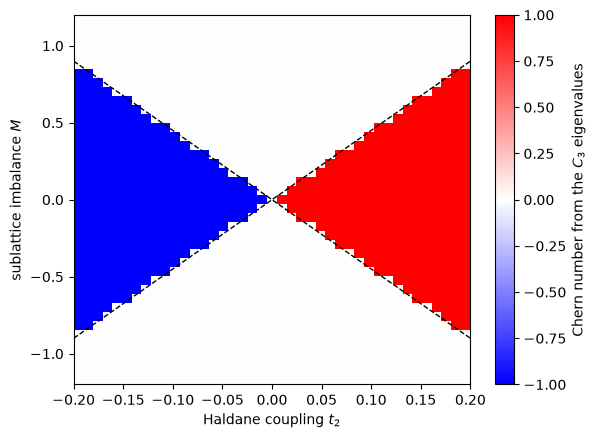

In [3]:
t2s = np.linspace(-0.2,0.2,41) # Haldane coupling
Ms = np.linspace(-1.2,1.2,41) # sublattice imbalance
Cmap = np.zeros((len(Ms),len(t2s)))
for (i,M) in enumerate(Ms):
    for (j,t2) in enumerate(t2s):
        h = g.get_hamiltonian(has_spin=False)
        h.add_haldane(t2) # Haldane coupling
        h.add_sublattice_imbalance(M) # sublattice imbalance
        try: c = h.get_chern_mod_n(n=3,center=g.r[0]) # Chern number modulo 3
        except ValueError: c = np.nan # the gap closes
        Cmap[i,j] = c-3 if c==2 else c # 2 is C=-1
plt.imshow(Cmap,origin="lower",aspect="auto",cmap="bwr",vmin=-1,vmax=1,
           extent=[t2s[0],t2s[-1],Ms[0],Ms[-1]])
plt.colorbar(label="Chern number from the $C_3$ eigenvalues")
plt.plot(t2s,4.5*t2s,color="black",lw=1,ls="--") ; plt.plot(t2s,-4.5*t2s,color="black",lw=1,ls="--")
plt.xlabel("Haldane coupling $t_2$") ; plt.ylabel("sublattice imbalance $M$")
plt.ylim(Ms[0],Ms[-1]) ; plt.show()

The map has the two lobes of the Haldane phase diagram: $C=1$ for $t_2>0$ and $C=-1$ for
$t_2<0$, inside the dashed lines $|M|=4.5|t_2|$, where the gap closes at one valley, and $C=0$
outside. For a cross-check we compare with the Chern number from the Berry curvature along the
line $t_2=0.15$.

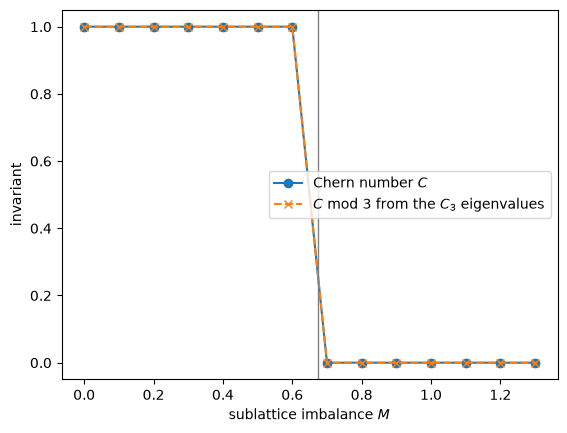

In [4]:
Ms1 = np.linspace(0.,1.3,14)
C3s,Cs = [],[]
for M in Ms1:
    h = g.get_hamiltonian(has_spin=False)
    h.add_haldane(0.15) ; h.add_sublattice_imbalance(M)
    C3s.append(h.get_chern_mod_n(n=3,center=g.r[0])) # from three momenta
    Cs.append(h.get_chern(nk=30)) # from the Berry curvature on a k-mesh
plt.plot(Ms1,Cs,marker="o",label="Chern number $C$")
plt.plot(Ms1,C3s,marker="x",ls="--",label="$C$ mod 3 from the $C_3$ eigenvalues")
plt.axvline(4.5*0.15,color="gray",lw=1)
plt.xlabel("sublattice imbalance $M$") ; plt.ylabel("invariant")
plt.legend() ; plt.show()

The two curves agree at every point, and both jump between $M=0.6$ and $M=0.7$, around the
critical value $4.5\,t_2=0.675$.

### Z2 invariant from the inversion eigenvalues
We take the Kane-Mele model and multiply the hopping of the bonds along $x$ by $s$. This keeps
the inversion about the bond center. At $s=2$ the two Dirac cones merge at a
time-reversal-invariant momentum, where the Kane-Mele term vanishes, so the gap closes there.
Beyond it the strong bonds form a trivial insulator of dimers. We compare the parity $Z_2$ with
the $Z_2$ from the flow of the hybrid Wannier centers, `topology.z2_invariant(h)`, which returns
$(-1)^\nu$.

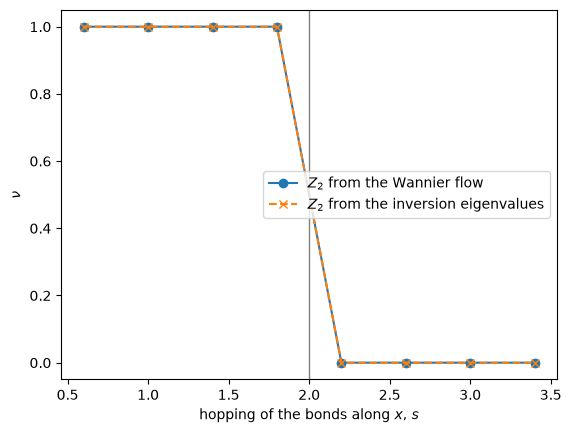

In [5]:
def kane_mele(s):
    def fun(r1,r2):
        dr = r1 - r2
        if abs(np.linalg.norm(dr)-1.)>1e-4: return 0.
        return s if abs(dr[1])<1e-4 else 1. # the bonds along x
    h = g.get_hamiltonian(fun=fun,has_spin=True)
    h.add_kane_mele(0.1) # spin-orbit coupling
    return h

ss = [0.6,1.,1.4,1.8,2.2,2.6,3.,3.4]
Zp,Zw = [],[]
for s in ss:
    h = kane_mele(s)
    Zp.append(h.get_parity_z2()) # from the inversion eigenvalues at four momenta
    Zw.append((1-topology.z2_invariant(h,nk=30,nt=30,write=False))/2) # from the Wannier flow
plt.plot(ss,Zw,marker="o",label="$Z_2$ from the Wannier flow")
plt.plot(ss,Zp,marker="x",ls="--",label="$Z_2$ from the inversion eigenvalues")
plt.axvline(2.,color="gray",lw=1)
plt.xlabel("hopping of the bonds along $x$, $s$") ; plt.ylabel("$\\nu$")
plt.legend() ; plt.show()

Both give $\nu=1$ below $s=2$ and $\nu=0$ above it. The parity formula needs four
diagonalizations, while the Wannier flow needs a Wilson loop at every momentum of half the
Brillouin zone. The price is that the parity formula needs inversion: with a sublattice
imbalance, which breaks it, only the Wannier flow works.

### Comparison with the literature
The relations between the rotation eigenvalues and the Chern number modulo $n$, for $C_2$, $C_3$,
$C_4$ and $C_6$ and with the factor $(-1)^F$ of a spinful system, are derived in Ref. [1]. The parity formula
of the $Z_2$ invariant is Ref. [2].

[1] C. Fang, M. J. Gilbert and B. A. Bernevig, Bulk topological invariants in noninteracting point
group symmetric insulators, Phys. Rev. B 86, 115112 (2012), arXiv:1207.5767

[2] L. Fu and C. L. Kane, Topological insulators with inversion symmetry, Phys. Rev. B 76, 045302
(2007), cond-mat/0611341